# DDP vs FSDP: training one model on many GPUs, step by step

**TL;DR.** Training a language model with Adam in mixed precision costs about **16 bytes per parameter** of model state before a single activation is stored. Plain data parallelism (DDP, *DistributedDataParallel*) keeps all 16 bytes on every GPU, so a 7B-parameter model needs about **112 GB per GPU** and does not fit on an 80 GB card no matter how many cards we add. FSDP (*Fully Sharded Data Parallel*) splits that state across the N GPUs, which brings the same model to about **14 GB per GPU on 8 GPUs**. The price is communication: FSDP moves **3Ψ** elements per GPU per step against DDP's **2Ψ** (Ψ = number of parameters), **1.5×** more, plus extra synchronisation points per layer.

We do not ask you to take any of this on trust. The notebook builds a small simulator of N GPUs in one process, implements DDP and FSDP from the collective operations up, and checks both against single-process training on the same data (final weights agree to ~2e-7). Memory and bytes sent are *counted from real tensors*; times are *modelled* and always labelled as such.

| section | what we do | key number |
|---|---|---|
| 1 | Where the memory goes | 16 bytes / parameter |
| 2 | DDP, one step, from the ring all-reduce up | 2Ψ(N−1)/N bytes sent per GPU |
| 3 | Hiding DDP's communication behind the backward pass | exposed communication vs bucket size (modelled) |
| 4 | Why DDP stops scaling | 7B needs 112 GB vs an 80 GB GPU |
| 5 | FSDP, one step, from the ring up | 3Ψ communication, peak memory ≈ 16Ψ/N + one unit |
| 6 | Choosing the wrapping unit | whole-model wrapping loses most of the saving |
| 7 | Checking against PyTorch's own DDP and FSDP | weights agree to ~1e-7 |
| 8 | Side by side | table of memory, communication, when to use which |

*Hardware and scale, stated plainly:* everything measured here is a 9,668-parameter MLP on 4 simulated ranks on a Mac CPU. The 7B / 70B numbers are arithmetic from the formulas in Section 1, not measurements. Prerequisite: what a gradient and an optimizer step are (see `numerics/02_mixed_precision_training`).

In [1]:
import io, math, time, json, inspect, subprocess, sys, tempfile, textwrap
from pathlib import Path
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import Image, display
import dist_kit as dk

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
ASSETS = Path("../../assets/distributed").resolve(); ASSETS.mkdir(parents=True, exist_ok=True)
COL = {"params": "#1c7ed6", "grads": "#2f9e44", "optimizer": "#7048e8", "gathered params": "#e8590c", "gathered grads": "#c92a2a"}
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail)); print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")
def fig_png(fig, dpi=80):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=dpi); plt.close(fig); return buf.getvalue()
def save_gif(frames, path, ms=170, hold_last=1200):
    imgs = [PILImage.open(io.BytesIO(b)).convert("RGB").convert("P", palette=PILImage.ADAPTIVE, colors=128) for b in frames]
    dur = [ms] * len(imgs); dur[-1] = hold_last
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=dur, loop=0, optimize=True, disposal=2); return path
N, LR, STEPS = 4, 1e-2, 5
xs, ys, X, Y = dk.make_data(N)
PSI = dk.nparams(dk.make_model())
print("torch", torch.__version__, "| toy model parameters Psi =", PSI, "| ranks N =", N, "| bytes/param (fp32) =", dk.F32)

torch 2.15.0 | toy model parameters Psi = 9668 | ranks N = 4 | bytes/param (fp32) = 4


## 1. Where the memory goes

To see why one GPU cannot hold a large model, count the bytes for **one** parameter. Take a weight `w = 0.5` trained with Adam in mixed precision (bf16 compute, fp32 master copy, as in `numerics/02`):

| thing stored for that one weight | bytes |
|---|---|
| bf16 weight used in forward/backward | 2 |
| bf16 gradient | 2 |
| fp32 master weight | 4 |
| Adam first moment *m* (fp32) | 4 |
| Adam second moment *v* (fp32) | 4 |
| **total** | **16** |

In general, with Ψ parameters the model state is **(2 + 2 + K)·Ψ bytes with K = 12** for Adam with an fp32 master copy (Rajbhandari et al., 2020, the ZeRO paper, uses exactly this accounting). Only 2Ψ of the 16Ψ is the "model" you would ship; 12Ψ is optimizer state. Activations come on top and depend on batch size and sequence length, so we leave them out here and return to them in the large-scale notebook.

The system-level consequence is simple and a little brutal: memory per GPU scales with the *whole* model, not with your share of the work.

In [2]:
def state_gb(psi, N=1, stage=0): return dk.state_bytes_per_gpu(psi, N, stage) / 1e9
rows = [("1B", 1e9), ("7B", 7e9), ("13B", 13e9), ("70B", 70e9)]
print(f"{'model':6s} {'state (GB)':>11s} {'DDP, any N':>11s} {'FSDP N=8':>10s} {'FSDP N=64':>10s}   fits 80 GB GPU? (DDP / FSDP-8 / FSDP-64)")
for name, psi in rows:
    d, f8, f64 = state_gb(psi, 8, 0), state_gb(psi, 8, 3), state_gb(psi, 64, 3)
    fits = " / ".join("yes" if v < 80 else "NO " for v in (d, f8, f64))
    print(f"{name:6s} {16*psi/1e9:11.0f} {d:11.0f} {f8:10.1f} {f64:10.1f}   {fits}")
check("16 bytes/param: 7B model state is 112 GB", abs(state_gb(7e9) - 112) < 1e-6)
check("FSDP on 8 GPUs divides 7B state to 14 GB", abs(state_gb(7e9, 8, 3) - 14) < 1e-6)

model   state (GB)  DDP, any N   FSDP N=8  FSDP N=64   fits 80 GB GPU? (DDP / FSDP-8 / FSDP-64)
1B              16          16        2.0        0.2   yes / yes / yes
7B             112         112       14.0        1.8   NO  / yes / yes
13B            208         208       26.0        3.2   NO  / yes / yes
70B           1120        1120      140.0       17.5   NO  / NO  / yes
PASS - 16 bytes/param: 7B model state is 112 GB 
PASS - FSDP on 8 GPUs divides 7B state to 14 GB 


The table is the headline in miniature: DDP's column does not move with N, FSDP's columns do. A 7B model is **112 GB under DDP** (does not fit an 80 GB card) and **14 GB under FSDP on 8 GPUs**; a 70B model needs 1,120 GB under DDP and still **17.5 GB per GPU on 64 GPUs**. The cost of that saving has to appear somewhere, and it appears in communication. To see exactly where, we start with the simpler scheme.

## 2. Data parallelism with DDP

**A tiny example first.** Four GPUs, one parameter `w` with value 1.0 on every GPU. Each GPU sees different data and computes a local gradient: `g = [0.4, 0.8, 0.2, 0.6]`. The correct gradient for the combined batch is the mean, **0.5**. DDP's whole job is to get every GPU to hold 0.5 and take the same optimizer step, so the four copies of `w` stay identical. The operation that does it is called **all-reduce**: every rank contributes a tensor, every rank receives the sum.

**General definition.** DDP (as in Li et al., 2020, *PyTorch Distributed*) keeps one full replica of the model per GPU. One step is:

1. each GPU runs forward and backward on its own micro-batch → local gradients,
2. **all-reduce** the gradients (sum, then divide by N),
3. each GPU runs the *same* optimizer step on the *same* averaged gradient → replicas remain bit-identical.

**How all-reduce is implemented.** On a ring of N GPUs, a tensor is cut into N chunks and the algorithm runs in two phases of N−1 steps each: **reduce-scatter** (each chunk travels around the ring being added to, until one GPU holds the fully summed chunk), then **all-gather** (the summed chunks travel around again until everyone has all of them). Each phase sends (N−1)/N of the tensor per GPU, so all-reduce sends **2(N−1)/N · size** per GPU, which is nearly independent of N for large N. Below we run this ring explicitly on 4 ranks with an 8-number tensor and watch the chunks move.

In [3]:
vecs = [torch.arange(8.) * (r + 1) for r in range(N)]           # rank r holds [0,1,..,7]*(r+1)
out, sent, log = dk.ring_all_reduce(vecs)
for phase, step, msgs in log:
    print(f"{phase:14s} step {step}: " + "  ".join(f"rank{s}->rank{d} chunk{c}" for s, d, c in msgs))
want = sum(vecs)
print("\nrank 0 result :", out[0].tolist()); print("true sum       :", want.tolist())
print("bytes sent per rank:", sent, "| formula 2(N-1)/N * size =", 2 * (N - 1) / N * 8 * dk.F32)
check("ring all-reduce returns the exact sum on every rank", all(torch.equal(o, want) for o in out))
check("ring all-reduce sends 2(N-1)/N * size bytes per rank", all(abs(s - 2 * (N - 1) / N * 8 * 4) < 1e-9 for s in sent))
# all-reduce == reduce-scatter followed by all-gather  (this identity is what FSDP exploits)
c = dk.Comm(N); rs = c.reduce_scatter(vecs); ag = c.all_gather(rs)
check("all-reduce == reduce-scatter + all-gather", torch.equal(ag, want), f"bytes: {c.sent:.0f} = {2*(N-1)/N*8*4:.0f}")

reduce-scatter step 0: rank0->rank1 chunk0  rank1->rank2 chunk1  rank2->rank3 chunk2  rank3->rank0 chunk3
reduce-scatter step 1: rank0->rank1 chunk3  rank1->rank2 chunk0  rank2->rank3 chunk1  rank3->rank0 chunk2
reduce-scatter step 2: rank0->rank1 chunk2  rank1->rank2 chunk3  rank2->rank3 chunk0  rank3->rank0 chunk1
all-gather     step 0: rank0->rank1 chunk1  rank1->rank2 chunk2  rank2->rank3 chunk3  rank3->rank0 chunk0
all-gather     step 1: rank0->rank1 chunk0  rank1->rank2 chunk1  rank2->rank3 chunk2  rank3->rank0 chunk3
all-gather     step 2: rank0->rank1 chunk3  rank1->rank2 chunk0  rank2->rank3 chunk1  rank3->rank0 chunk2

rank 0 result : [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0]
true sum       : [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0]
bytes sent per rank: [48, 48, 48, 48] | formula 2(N-1)/N * size = 48.0
PASS - ring all-reduce returns the exact sum on every rank 
PASS - ring all-reduce sends 2(N-1)/N * size bytes per rank 
PASS - all-reduce == reduce-scatter + all-

Two things to notice in the log. First, in the reduce-scatter phase every rank sends exactly one chunk per step, so all links are busy at once; that is why the ring is bandwidth-optimal. Second, the last check shows that **all-reduce is literally reduce-scatter followed by all-gather**. DDP does both halves on the gradients; we will see in Section 5 that FSDP splits them apart and puts the optimizer step in between.

Now one full DDP step. `DDPSim` below holds N independent replicas, runs real forward/backward on each, all-reduces every gradient tensor through the byte-counting `Comm`, and steps N separate Adam optimizers. The cell prints the method so you can read the three stages above as code.

In [4]:
print(inspect.getsource(dk.DDPSim.step))

    def step(self, xs, ys):
        N, tr = self.N, self.tr; tr.snap("start of step", self._persist())
        losses = []
        for r in range(N):                                                       # 1) local forward+backward
            self.opts[r].zero_grad(); loss = ((self.models[r](xs[r]) - ys[r]) ** 2).mean(); loss.backward(); losses.append(loss.item())
        tr.snap("local backward done (full grads)", self._persist())
        ps = [list(m.parameters()) for m in self.models]
        for j in range(len(ps[0])):                                              # 2) all-reduce grads, average
            g = self.comm.all_reduce([ps[r][j].grad.flatten() for r in range(N)]) / N
            for r in range(N): ps[r][j].grad = g.view_as(ps[r][j]).clone()
        tr.snap("all-reduce grads", self._persist())
        for r in range(N): self.opts[r].step()                                   # 3) identical optimizer step
        tr.snap("optimizer step", self._persist())
        return sum

In [5]:
base, base_losses = dk.baseline_train(STEPS, LR, N)             # single process, one batch of 64 samples
ddp = dk.DDPSim(N, LR)
ddp_losses = [ddp.step(xs, ys) for _ in range(STEPS)]
err = (ddp.flat(0) - base).abs().max().item()
rep = max((ddp.flat(0) - ddp.flat(r)).abs().max().item() for r in range(1, N))
per_step = ddp.comm.sent / STEPS
print(f"loss  baseline {[round(l, 4) for l in base_losses]}\nloss  DDP      {[round(l, 4) for l in ddp_losses]}")
print(f"max |w_DDP - w_baseline| = {err:.2e}   max replica disagreement = {rep:.1e}")
print(f"bytes sent per rank per step: {per_step:,.0f}  | 2(N-1)/N * Psi * 4 = {2*(N-1)/N*PSI*4:,.0f}")
check("DDP final weights == single-process training (<1e-5)", err < 1e-5, f"{err:.1e}")
check("DDP replicas are bit-identical after training", rep == 0.0)
check("DDP sends 2(N-1)/N * 4*Psi bytes per rank per step", abs(per_step - 2 * (N - 1) / N * PSI * 4) < 1)

loss  baseline [1.1128, 0.9936, 0.9183, 0.8727, 0.8378]
loss  DDP      [1.1128, 0.9936, 0.9183, 0.8727, 0.8378]
max |w_DDP - w_baseline| = 1.94e-07   max replica disagreement = 0.0e+00
bytes sent per rank per step: 58,008  | 2(N-1)/N * Psi * 4 = 58,008
PASS - DDP final weights == single-process training (<1e-5) | 1.9e-07
PASS - DDP replicas are bit-identical after training 
PASS - DDP sends 2(N-1)/N * 4*Psi bytes per rank per step 


In our setting, DDP reproduces the single-process run to **~2e-7** in the weights, and the four replicas agree exactly, which is the correctness bar: data parallelism is supposed to be a pure speed-up, not a different algorithm. The measured **58,008 bytes sent per rank per step** equals 2(N−1)/N · 4Ψ, i.e. 1.5 × 4Ψ for N = 4, approaching 2 × 4Ψ as N grows. However, the all-reduce above sits *after* the backward pass in our simulator, and on a real cluster that would leave every GPU idle while the network works. The next section is about not doing that.

## 3. Overlapping communication in DDP

**Tiny example.** A model has 4 layers. Backward takes 10 ms per layer and all-reduce of one layer's gradient takes 6 ms. If we wait for the whole backward and then communicate, a step costs 4 × 10 + 4 × 6 = **64 ms**. But the gradient of the last layer is final after 10 ms, long before the first layer's backward finishes. If we start its all-reduce immediately on a separate stream, the network works while the GPU computes, and the step costs 4 × 10 + 6 = **46 ms**: only the last bucket's communication is exposed.

**General definition.** PyTorch's DDP registers a hook on every parameter's gradient; when a *bucket* of gradients (default `bucket_cap_mb=25`) is complete, it launches an asynchronous all-reduce for that bucket. Bucketing is a trade-off: tiny buckets start communication earlier but each all-reduce call pays a fixed latency α; huge buckets amortise latency but start late and expose more communication at the end.

**Implementation, modelled.** The cell below is a simple discrete-event model: 32 layers, 10 ms backward per layer, 7 ms per layer of pure transfer time, α = 6 ms per call, one communication stream. These constants are **assumptions chosen for illustration, not measurements**; the shape of the curve is what matters.

 bucket (layers)  step ms  exposed comm ms
      no overlap      592              272
               1      426              106
               2      340               20
               4      354               34
               8      382               62
              16      438              118
              32      550              230
best bucket: 2 layers
PASS - overlap beats no-overlap (modelled) 
PASS - best bucket size is neither the smallest nor the largest (modelled) | best=2


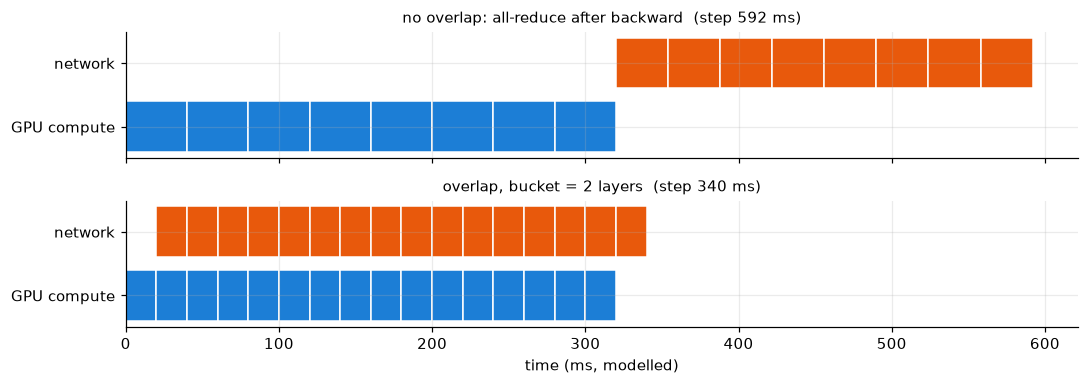

In [6]:
def backward_timeline(L=32, b=10.0, c=7.0, alpha=6.0, bucket=4, overlap=True):
    """Return (step_ms, exposed_comm_ms, bars). Bars: (stream, start, dur, label)."""
    t, comm_free, bars = 0.0, 0.0, []
    nb = math.ceil(L / bucket); total_comm = 0.0
    for j in range(nb):
        k = min(bucket, L - j * bucket); bars.append(("GPU", t, k * b, f"bwd {j}")); t += k * b
        dur = alpha + k * c; total_comm += dur
        if overlap: s = max(t, comm_free); bars.append(("NET", s, dur, f"AR {j}")); comm_free = s + dur
    end = max(t, comm_free) if overlap else t + total_comm
    if not overlap:
        s = t
        for j in range(nb): k = min(bucket, L - j * bucket); d = alpha + k * c; bars.append(("NET", s, d, f"AR {j}")); s += d
    return end, end - t, bars

print(f"{'bucket (layers)':>16s} {'step ms':>8s} {'exposed comm ms':>16s}")
no_ov = backward_timeline(bucket=4, overlap=False)
print(f"{'no overlap':>16s} {no_ov[0]:8.0f} {no_ov[1]:16.0f}")
results = {}
for bk in (1, 2, 4, 8, 16, 32):
    e, x, _ = backward_timeline(bucket=bk); results[bk] = (e, x); print(f"{bk:16d} {e:8.0f} {x:16.0f}")
best = min(results, key=lambda k: results[k][0])
print("best bucket:", best, "layers")
check("overlap beats no-overlap (modelled)", results[best][0] < no_ov[0])
check("best bucket size is neither the smallest nor the largest (modelled)", best not in (1, 32), f"best={best}")

fig, axs = plt.subplots(2, 1, figsize=(10, 3.6), sharex=True)
for ax, (title, e, bars) in zip(axs, [("no overlap: all-reduce after backward", no_ov[0], no_ov[2]), (f"overlap, bucket = {best} layers", results[best][0], backward_timeline(bucket=best)[2])]):
    for lane, s, d, lab in bars:
        ax.barh(0 if lane == "GPU" else 1, d, left=s, color="#1c7ed6" if lane == "GPU" else "#e8590c", edgecolor="white")
    ax.set_yticks([0, 1]); ax.set_yticklabels(["GPU compute", "network"]); ax.set_title(f"{title}  (step {e:.0f} ms)", fontsize=10)
axs[1].set_xlabel("time (ms, modelled)"); plt.tight_layout(); plt.savefig(ASSETS / "ddp_overlap_model.png", dpi=110); plt.show()

[FIGURE: top lane = GPU compute (blue), bottom lane = network (orange). **Notice** that in the overlapped schedule the orange bars start while the blue bars are still running, and only the final bucket sticks out past the end of compute.]

In this model, overlap cuts the step from **592 ms to 340 ms (−43%)** with the best bucket (2 layers), and the best bucket is a middle value rather than either extreme: 1-layer buckets pay the 6 ms call latency 32 times and become communication-bound (426 ms), while one 32-layer bucket exposes all its communication (550 ms). It is the same reason PyTorch ships a 25 MB default instead of per-tensor all-reduces. We stress that this is a model with assumed constants; on real hardware the exposed fraction depends on network bandwidth relative to compute, and when communication per layer exceeds compute per layer (c > b) overlap can no longer hide it. DDP with overlap is a good deal when the model fits. The next section is about what happens when it does not.

## 4. Why DDP stops scaling

Here is the failed baseline, stated plainly. We want to train a 7B-parameter model; we have 8 GPUs with 80 GB each. We launch DDP. **Symptom:** CUDA out-of-memory while allocating optimizer state, before the first step finishes. **Root cause:** Section 1's arithmetic: every replica needs 16 × 7 GB = 112 GB of state. **What we do about it:** adding GPUs does not help, because DDP's per-GPU memory is independent of N; the only remedies are a smaller model, a smaller optimizer state (e.g. 8-bit Adam, with its own accuracy cost), offloading, or sharding. (This failure is the textbook arithmetic, not a run we executed on 80 GB GPUs.)

The cell measures the claim on the toy: per-rank peak bytes of DDP against N, from the tracker that records every live tensor, next to what sharding will give us in Section 5.

  N  DDP peak B/rank  FSDP peak B/rank  ratio
  2          154,688           100,128   1.54
  4          154,688            66,704   2.32
  8          154,688            50,000   3.09
PASS - DDP per-rank peak memory does not depend on N 
PASS - FSDP per-rank peak memory falls as N grows 


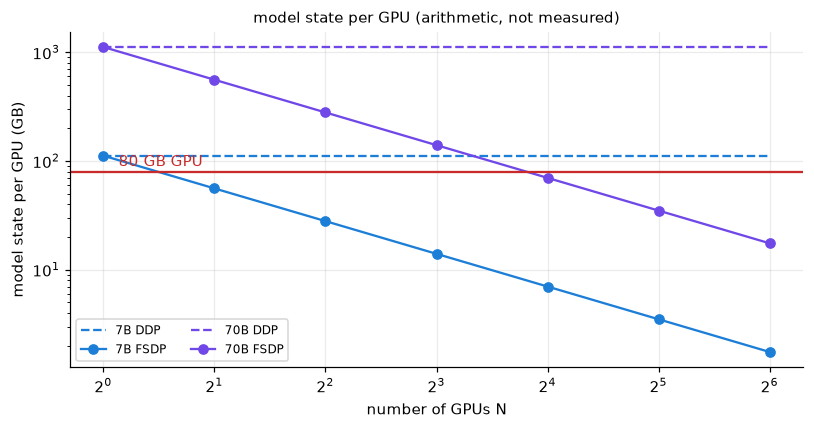

In [7]:
rows = []
for n in (2, 4, 8):
    xs_n, ys_n, _, _ = dk.make_data(n)
    d = dk.DDPSim(n, LR);  [d.step(xs_n, ys_n) for _ in range(2)]
    f = dk.ShardSim(n, LR, stage=3); [f.step(xs_n, ys_n) for _ in range(2)]
    rows.append((n, d.tr.peak, f.tr.peak))
print(f"{'N':>3s} {'DDP peak B/rank':>16s} {'FSDP peak B/rank':>17s} {'ratio':>6s}")
for n, a, b in rows: print(f"{n:3d} {a:16,d} {b:17,d} {a/b:6.2f}")
check("DDP per-rank peak memory does not depend on N", len({a for _, a, _ in rows}) == 1)
check("FSDP per-rank peak memory falls as N grows", rows[0][2] > rows[1][2] > rows[2][2])

Ns = np.array([1, 2, 4, 8, 16, 32, 64])
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, psi, c in (("7B", 7e9, "#1c7ed6"), ("70B", 70e9, "#7048e8")):
    ax.plot(Ns, [state_gb(psi, n, 0) for n in Ns], "--", color=c, label=f"{name} DDP"); ax.plot(Ns, [state_gb(psi, n, 3) for n in Ns], "-o", color=c, label=f"{name} FSDP")
ax.axhline(80, color="#c92a2a"); ax.text(1.1, 90, "80 GB GPU", color="#c92a2a")
ax.set_xscale("log", base=2); ax.set_yscale("log"); ax.set_xlabel("number of GPUs N"); ax.set_ylabel("model state per GPU (GB)"); ax.legend(ncol=2, fontsize=8)
ax.set_title("model state per GPU (arithmetic, not measured)", fontsize=10); plt.tight_layout(); plt.savefig(ASSETS / "memory_vs_gpus.png", dpi=110); plt.show()

[FIGURE: per-GPU model state against GPU count. **Notice** the dashed DDP lines are flat and sit above the red 80 GB line for both models; the 7B FSDP line crosses below it at N = 2 (56 GB) and the 70B line at N = 16 (70 GB).]

On the toy, DDP's per-rank peak is **154,688 bytes for every N** (= 4 × 4Ψ), while FSDP drops from **100,128 B at N = 2 to 66,704 B at N = 4 and 50,000 B at N = 8**, i.e. 1.5×, 2.3× and 3.1× below DDP. Sharding is therefore the right fix for the memory wall, but it cannot be free: a GPU that no longer owns the whole model has to borrow the rest of it every time it computes. That is the next section.

## 5. Sharding with FSDP

**A tiny example.** Take a 4-layer model with 4 numbers per layer on 4 GPUs. In DDP every GPU stores all 16 numbers. In FSDP, each layer's 4 numbers are cut into 4 slices and GPU *r* stores only slice *r* of every layer, 4 numbers in total. To run layer 2's forward, GPU 0 needs all 4 numbers of layer 2, so the four GPUs **all-gather** their slices (each sends its slice to the others), compute, then **immediately free** the 3 borrowed slices. Backward needs them again, so we all-gather a second time. The gradient of layer 2 is computed in full on every GPU from its own micro-batch, and **reduce-scatter** sums it across GPUs and hands each GPU only its own slice. Each GPU then updates its own slice, with an optimizer state that is also only a slice.

**General definition.** FSDP (Zhao et al., 2023, *PyTorch FSDP*; the same idea as ZeRO stage 3 in Rajbhandari et al., 2020) shards parameters, gradients and optimizer state across data-parallel ranks, and materialises one *unit* (a group of layers) of full parameters at a time. One step:

| stage | collective | what is in memory afterwards |
|---|---|---|
| forward, unit *u* | all-gather *u*'s params | shard + full *u* → freed after use |
| backward, unit *u* (in reverse) | all-gather *u*'s params again | shard + full *u* + full grad of *u* |
| | reduce-scatter *u*'s grad | grad **shard** only, full grad freed |
| optimizer | none | updates shard with shard of Adam state |

Communication per step is all-gather (Ψ) + all-gather (Ψ) + reduce-scatter (Ψ) = **3Ψ**, against DDP's 2Ψ, because the all-reduce is now split into a reduce-scatter of gradients, and the parameters have to be gathered twice. Peak memory is **16Ψ/N for persistent state plus one unit's full parameters and gradients**. The cell prints the implementation, then runs it.

In [8]:
print(inspect.getsource(dk.ShardSim.step))

    def step(self, xs, ys):
        N, tr, U, st = self.N, self.tr, len(self.units), self.stage
        self._held_full_grads = 0; held = {}; tr.snap("start of step", self._persist())
        acts, cur = [[None] * U for _ in range(N)], list(xs)
        for u, unit in enumerate(self.units):                                    # ---- forward
            if st == 3:
                full = self._gather(u); tr.transient["gathered params"] = full.numel() * F32; tr.snap(f"all-gather unit {u}", self._persist())
            else: full = self.full_unit(u)
            for r in range(N):
                acts[r][u] = cur[r]
                with torch.no_grad(): cur[r] = functional_call(unit, _unflat(unit, full), (cur[r],))
            tr.snap(f"forward unit {u}", self._persist())
            if st == 3: tr.transient["gathered params"] = 0; tr.snap(f"free unit {u}", self._persist())
        gs, losses = [], []
        for r in range(N):
            o = cur[r].detach().requires_grad_(); loss = ((o - y

In [9]:
from collections import Counter
fsdp = dk.ShardSim(N, LR, stage=3, per="layer")
fsdp_losses = [fsdp.step(xs, ys) for _ in range(STEPS)]
err_f = (fsdp.flat() - base).abs().max().item()
per_step_f = fsdp.comm.sent / STEPS
print(f"max |w_FSDP - w_baseline| = {err_f:.2e}")
print(f"bytes sent per rank per step: FSDP {per_step_f:,.0f}  vs DDP {per_step:,.0f}  -> ratio {per_step_f/per_step:.2f}x")
print("collectives in one FSDP step:", dict(Counter(n for n, _ in fsdp.comm.log[:3 * len(fsdp.units)])))
check("FSDP final weights == single-process training (<1e-5)", err_f < 1e-5, f"{err_f:.1e}")
check("FSDP sends 3(N-1)/N * 4*Psi bytes per rank per step", abs(per_step_f - 3 * (N - 1) / N * PSI * 4) < 1)
check("FSDP communication is 1.5x DDP", abs(per_step_f / per_step - 1.5) < 1e-9)
shard_params = sum(p.numel() for p in fsdp.shards[0]) * 4
check("persistent parameter bytes per rank = 4*Psi/N (up to padding)", abs(shard_params - PSI * 4 / N) / (PSI * 4 / N) < 0.01, f"{shard_params} vs {PSI*4/N:.0f}")

max |w_FSDP - w_baseline| = 1.94e-07
bytes sent per rank per step: FSDP 87,012  vs DDP 58,008  -> ratio 1.50x
collectives in one FSDP step: {'all_gather': 8, 'reduce_scatter': 4}
PASS - FSDP final weights == single-process training (<1e-5) | 1.9e-07
PASS - FSDP sends 3(N-1)/N * 4*Psi bytes per rank per step 
PASS - FSDP communication is 1.5x DDP 
PASS - persistent parameter bytes per rank = 4*Psi/N (up to padding) | 9668 vs 9668


In our setting, FSDP trains to the same weights as the single-process run (**~2e-7** max difference), sends **87,012 bytes per rank per step against DDP's 58,008, exactly 1.5×**, and issues 12 collectives per step for the 4 units (2 all-gathers and 1 reduce-scatter each). Each rank's persistent parameter shard is 4Ψ/N within 1% (the rest is padding so slices are equal). Next, the event trace: how many bytes does rank 0 hold at every moment of the last step, for DDP and for FSDP?

FSDP, rank 0, last step: live bytes by category
event                                params      grads  optimizer gathered p gathered g    total
start of step                         9,668          0     19,336          0          0   29,004
all-gather unit 0                     9,668          0     19,336      4,352          0   33,356
forward unit 0                        9,668          0     19,336      4,352          0   33,356
free unit 0                           9,668          0     19,336          0          0   29,004
all-gather unit 1                     9,668          0     19,336     16,640          0   45,644
forward unit 1                        9,668          0     19,336     16,640          0   45,644
free unit 1                           9,668          0     19,336          0          0   29,004
all-gather unit 2                     9,668          0     19,336     16,640          0   45,644
forward unit 2                        9,668          0     19,336     16,640   

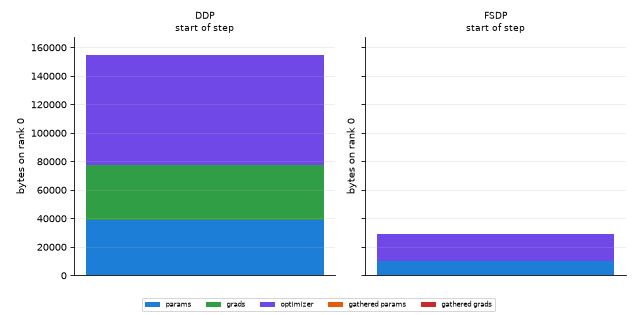

In [10]:
def last_step(tr):
    i = max(k for k, (n, _) in enumerate(tr.events) if n == "start of step"); return tr.events[i:]
ev_d, ev_f = last_step(ddp.tr), last_step(fsdp.tr)
print("FSDP, rank 0, last step: live bytes by category")
print(f"{'event':32s}" + "".join(f"{c[:10]:>11s}" for c in dk.Tracker.CATS) + f"{'total':>9s}")
for n, r in ev_f: print(f"{n:32s}" + "".join(f"{r[c]:11,d}" for c in dk.Tracker.CATS) + f"{sum(r.values()):9,d}")
print(f"\npeak: DDP {ddp.tr.peak:,d} B | FSDP {fsdp.tr.peak:,d} B | ratio {ddp.tr.peak/fsdp.tr.peak:.2f}x")
check("FSDP peak memory per rank is below DDP's", fsdp.tr.peak < ddp.tr.peak, f"{fsdp.tr.peak:,} vs {ddp.tr.peak:,}")

def draw_mem(ax, events, k, title, ymax):
    n, r = events[k]; bottom = 0
    for c in dk.Tracker.CATS:
        ax.bar(0, r[c], bottom=bottom, color=COL[c], width=0.6, label=c); bottom += r[c]
    ax.set_ylim(0, ymax * 1.08); ax.set_xticks([]); ax.set_title(f"{title}\n{n}", fontsize=9); ax.set_ylabel("bytes on rank 0")
ymax = max(ddp.tr.peak, fsdp.tr.peak); frames = []; F = 24
for f in range(F):
    fig, axs = plt.subplots(1, 2, figsize=(8.5, 4.2), sharey=True)
    draw_mem(axs[0], ev_d, round(f * (len(ev_d) - 1) / (F - 1)), "DDP", ymax); draw_mem(axs[1], ev_f, round(f * (len(ev_f) - 1) / (F - 1)), "FSDP", ymax)
    h, l = axs[1].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=5, fontsize=7); plt.tight_layout(rect=(0, 0.07, 1, 1)); frames.append(fig_png(fig, 75))
gif = save_gif(frames, ASSETS / "ddp_vs_fsdp_memory.gif"); display(Image(filename=str(gif)))

[FIGURE: stacked bars of rank 0's live bytes during one training step, DDP left, FSDP right, same y-axis. **Notice** the DDP bar is tall from the first frame (all parameters and Adam state are resident) and grows again when gradients appear; the FSDP bar is short at rest and rises by only one unit's orange/red blocks at a time.]

The trace shows the shape of the saving. FSDP's persistent state (blue, purple) is a quarter of DDP's, and the orange "gathered params" and red "gathered grads" blocks appear for one unit and vanish. Our toy peak is **66,704 B against 154,688 B, a 2.3× reduction on 4 ranks**, not 4×, because the one gathered unit and its gradient are not small compared with a 9,668-parameter model. With 32 or more transformer blocks the transient term shrinks relative to the 16Ψ/N persistent state, which is why the saving approaches N for real models (arithmetic, not measured here). That brings up the question of how much we gather at once.

## 6. Choosing the wrapping unit

The *unit* is the group of layers FSDP gathers together. We tried three settings on the same toy, all with identical numerics: one unit per layer (4 units), one per half of the model (2 units), and the **whole model as a single unit**. The last is what you get if you wrap only the outermost module, which is the easy thing to do.

**Symptom:** with the whole model as one unit, peak memory barely improves on DDP. **Root cause:** the unit is gathered in full, so at that moment every rank holds all parameters, and in backward it also holds the full gradient before reduce-scatter, so the "sharded" run momentarily holds almost as much as DDP. **What we did instead:** wrap per transformer block, so that the transient is one block, not one model.

In [11]:
rows = []
for per in ("layer", "pair", "model"):
    f = dk.ShardSim(N, LR, stage=3, per=per); [f.step(xs, ys) for _ in range(STEPS)]
    err_u = (f.flat() - base).abs().max().item(); ncoll = len(f.comm.log) // STEPS
    rows.append((per, len(f.units), f.tr.peak, ncoll, f.comm.sent / STEPS, err_u))
print(f"{'wrap unit':>10s} {'#units':>6s} {'peak B/rank':>12s} {'vs DDP':>7s} {'collectives/step':>17s} {'bytes sent/step':>16s} {'weights err':>12s}")
for per, nu, pk, nc, by, e in rows: print(f"{per:>10s} {nu:6d} {pk:12,d} {pk/ddp.tr.peak:7.2f} {nc:17d} {by:16,.0f} {e:12.1e}")
check("finer wrapping lowers peak memory: layer < pair < model", rows[0][2] < rows[1][2] < rows[2][2])
check("wrapping granularity does not change bytes sent or numerics", len({round(r[4]) for r in rows}) == 1 and all(r[5] < 1e-5 for r in rows))
check("whole-model wrapping keeps most of DDP's memory", rows[2][2] > 0.6 * ddp.tr.peak, f"{rows[2][2]/ddp.tr.peak:.2f} of DDP")

 wrap unit #units  peak B/rank  vs DDP  collectives/step  bytes sent/step  weights err
     layer      4       66,704    0.43                12           87,012      1.9e-07
      pair      2       75,408    0.49                 6           87,012      1.9e-07
     model      1      106,348    0.69                 3           87,012      1.9e-07
PASS - finer wrapping lowers peak memory: layer < pair < model 
PASS - wrapping granularity does not change bytes sent or numerics 
PASS - whole-model wrapping keeps most of DDP's memory | 0.69 of DDP


In our setting the peak is **66,704 B** with 4 units, **75,408 B** with 2, and **106,348 B (69% of DDP's)** with one, while bytes sent and final weights are identical across all three. The cost of finer units is the number of collectives (12 per step at 4 units against 3 at one unit): each pays the latency α from Section 3, which is why real FSDP overlaps the next unit's all-gather with the current unit's compute (*forward prefetch* and *backward prefetch* in PyTorch) rather than waiting. We do not measure prefetch here: it only matters when there is a real network. We now check the simulator against PyTorch's own implementations.

## 7. Checking against PyTorch

A simulator that agrees with itself proves little, so the cell below launches **real** `torch.nn.parallel.DistributedDataParallel` and `torch.distributed.fsdp.FullyShardedDataParallel` on 4 processes with the `gloo` backend, the same model, same data, same Adam, 5 steps, and compares their final weights to the single-process baseline. On this Mac we pass `device_id=torch.device("cpu")` to FSDP, which otherwise tries to use the `mps` device and fails. FSDP wraps each `nn.Linear` as its own unit (`ModuleWrapPolicy`).

In [12]:
SCRIPT = textwrap.dedent("""
    import os, sys, json, torch, torch.nn as nn, torch.distributed as dist, torch.multiprocessing as mp
    from torch.nn.parallel import DistributedDataParallel as DDP
    from torch.distributed.fsdp import FullyShardedDataParallel as FSDP
    from torch.distributed.fsdp.wrap import ModuleWrapPolicy
    sys.path.insert(0, sys.argv[1]); import dist_kit as dk
    def run(rank, N, mode, port, out):
        os.environ.update(MASTER_ADDR="127.0.0.1", MASTER_PORT=str(port))
        dist.init_process_group("gloo", rank=rank, world_size=N)
        m = dk.make_model(); xs, ys, _, _ = dk.make_data(N)
        w = DDP(m) if mode == "ddp" else FSDP(m, use_orig_params=True, device_id=torch.device("cpu"), auto_wrap_policy=ModuleWrapPolicy({nn.Linear}))
        opt = torch.optim.Adam(w.parameters(), lr=1e-2)
        for _ in range(5):
            opt.zero_grad(); ((w(xs[rank]) - ys[rank]) ** 2).mean().backward(); opt.step()
        local = sum(p.numel() for p in w.parameters())
        if mode == "fsdp":
            with FSDP.summon_full_params(w): flat = torch.cat([p.detach().flatten() for p in w.parameters()])
        else: flat = torch.cat([p.detach().flatten() for p in w.parameters()])
        if rank == 0: json.dump({"flat": flat.tolist(), "local_numel": local}, open(out, "w"))
        dist.destroy_process_group()
    if __name__ == "__main__":
        N, mode, port, out = int(sys.argv[2]), sys.argv[3], int(sys.argv[4]), sys.argv[5]
        mp.spawn(run, args=(N, mode, port, out), nprocs=N)
""")
tmp = Path(tempfile.mkdtemp()); (tmp / "real_dp.py").write_text(SCRIPT)
real = {}
for mode, port in (("ddp", 29631), ("fsdp", 29632)):
    out = tmp / f"{mode}.json"; t0 = time.time()
    r = subprocess.run([sys.executable, str(tmp / "real_dp.py"), str(Path.cwd()), str(N), mode, str(port), str(out)], capture_output=True, text=True, timeout=300)
    assert r.returncode == 0, r.stderr[-1500:]
    real[mode] = json.load(open(out)); print(f"real {mode.upper():4s}: ran in {time.time()-t0:4.1f}s on {N} gloo processes")
for mode in ("ddp", "fsdp"):
    w = torch.tensor(real[mode]["flat"]); e = (w - base).abs().max().item()
    print(f"real {mode.upper():4s}: max |w - w_baseline| = {e:.2e} | parameters held by rank 0 = {real[mode]['local_numel']:,} (Psi = {PSI:,})")
    check(f"real PyTorch {mode.upper()} == single-process training (<1e-5)", e < 1e-5, f"{e:.1e}")
check("real FSDP rank holds ~Psi/N parameters, real DDP holds Psi", real["ddp"]["local_numel"] == PSI and abs(real["fsdp"]["local_numel"] - PSI / N) / (PSI / N) < 0.35, f"{real['fsdp']['local_numel']} vs {PSI/N:.0f}")

real DDP : ran in 26.2s on 4 gloo processes


real FSDP: ran in 29.9s on 4 gloo processes
real DDP : max |w - w_baseline| = 2.05e-07 | parameters held by rank 0 = 9,668 (Psi = 9,668)
PASS - real PyTorch DDP == single-process training (<1e-5) | 2.0e-07
real FSDP: max |w - w_baseline| = 1.94e-07 | parameters held by rank 0 = 2,417 (Psi = 9,668)
PASS - real PyTorch FSDP == single-process training (<1e-5) | 1.9e-07
PASS - real FSDP rank holds ~Psi/N parameters, real DDP holds Psi | 2417 vs 2417


Both real implementations agree with the baseline (**2.05e-07** for DDP, **1.94e-07** for FSDP, the latter identical to our simulator), and real FSDP rank 0 holds **2,417 parameters, exactly Ψ/4**, while real DDP holds all 9,668. In our setting that confirms the simulator is modelling the actual algorithms and not an idealisation of them. Two things we did **not** check: wall-clock speed (a CPU `gloo` run of a 9,668-parameter model is dominated by process startup, so any timing would be meaningless) and behaviour on GPUs with NCCL.

## 8. Side by side

The first table is measured on our toy (4 ranks, Ψ = 9,668, fp32 Adam); the second is the same formulas applied to 7B and 70B with bf16 parameters and gradients and the communication times **modelled** with an assumed 300 GB/s effective per-GPU bus bandwidth (an assumption, not a measurement of any specific interconnect).

In [13]:
print("MEASURED on the toy (N=4):")
print(f"{'':28s}{'DDP':>12s}{'FSDP (per layer)':>18s}")
print(f"{'peak bytes / rank':28s}{ddp.tr.peak:12,d}{fsdp.tr.peak:18,d}")
print(f"{'persistent param bytes':28s}{PSI*4:12,d}{shard_params:18,d}")
print(f"{'bytes sent / rank / step':28s}{per_step:12,.0f}{per_step_f:18,.0f}")
print(f"{'collectives / step':28s}{len(ddp.comm.log)//STEPS:12d}{len(fsdp.comm.log)//STEPS:18d}")
print("\nMODELLED for large models (bf16 params+grads, Adam fp32 state, N=8, assumed 300 GB/s per GPU):")
BW = 300e9
print(f"{'model':6s}{'DDP GB/GPU':>12s}{'FSDP GB/GPU':>13s}{'DDP comm GB':>13s}{'FSDP comm GB':>14s}{'DDP ms':>8s}{'FSDP ms':>9s}")
for name, psi in [("7B", 7e9), ("70B", 70e9)]:
    n = 8; dc = 2 * (n - 1) / n * 2 * psi / 1e9; fc = 3 * (n - 1) / n * 2 * psi / 1e9
    print(f"{name:6s}{state_gb(psi,n,0):12.0f}{state_gb(psi,n,3):13.1f}{dc:13.1f}{fc:14.1f}{dc*1e9/BW*1e3:8.0f}{fc*1e9/BW*1e3:9.0f}")
check("collectives per step: FSDP issues 3 per unit", len(fsdp.comm.log) // STEPS == 3 * len(fsdp.units))

MEASURED on the toy (N=4):
                                     DDP  FSDP (per layer)
peak bytes / rank                154,688            66,704
persistent param bytes            38,672             9,668
bytes sent / rank / step          58,008            87,012
collectives / step                     8                12

MODELLED for large models (bf16 params+grads, Adam fp32 state, N=8, assumed 300 GB/s per GPU):
model   DDP GB/GPU  FSDP GB/GPU  DDP comm GB  FSDP comm GB  DDP ms  FSDP ms
7B             112         14.0         24.5          36.8      82      122
70B           1120        140.0        245.0         367.5     817     1225
PASS - collectives per step: FSDP issues 3 per unit 


| | DDP | FSDP (full shard) |
|---|---|---|
| model state per GPU | 16Ψ (independent of N) | 16Ψ/N + one unit's full params and grads |
| communication per GPU per step | 2Ψ (all-reduce) | 3Ψ (2 all-gathers + reduce-scatter) |
| collectives per step | ~1 per bucket | 3 per unit |
| what hides the communication | gradient buckets overlapped with backward | prefetching the next unit's all-gather |
| checkpointing | any rank can save | shards must be gathered or saved sharded |
| use when | the model plus optimizer state fit on one GPU with room for activations | they do not, or you want the memory for a larger batch |

On the modelled 7B case with an assumed 300 GB/s per GPU, DDP's all-reduce moves 24.5 GB and takes about 82 ms per step against FSDP's 36.8 GB and about 122 ms: a 40 ms difference that prefetching has to hide, and that matters far less than the 112 GB → 14 GB memory difference.

The decision rule we apply is short. **If the state fits, use DDP**: it is simpler and sends a third less. **If it does not, shard**, and wrap per block. The costs we measured and modelled are 1.5× communication, more collectives, and a more involved checkpoint format.

## Closing thoughts

Data parallelism with all-reduce is the older idea; ZeRO (Rajbhandari et al., 2020) observed that the replicated optimizer state, gradients and parameters in DDP are redundant, and PyTorch FSDP (Zhao et al., 2023) made the stage-3 variant a first-class module. What is still open for us: the gather-twice cost can be reduced by keeping parameters resident between forward and backward (PyTorch's `reshard_after_forward=False`, at the price of memory), and on large clusters the all-gathers should stay inside a node (hybrid sharding), neither of which we measured. Real throughput on GPUs with NCCL is also unmeasured here. The next notebook, `02_zero_deepspeed_large_scale.ipynb`, takes the three ZeRO stages apart, looks at DeepSpeed's configuration, and puts data parallelism together with tensor and pipeline parallelism for models that no single sharding strategy handles alone.

In [14]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n}")
failed = [n for n, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed"); assert not failed, failed

 #  status  check
 1  PASS    16 bytes/param: 7B model state is 112 GB
 2  PASS    FSDP on 8 GPUs divides 7B state to 14 GB
 3  PASS    ring all-reduce returns the exact sum on every rank
 4  PASS    ring all-reduce sends 2(N-1)/N * size bytes per rank
 5  PASS    all-reduce == reduce-scatter + all-gather
 6  PASS    DDP final weights == single-process training (<1e-5)
 7  PASS    DDP replicas are bit-identical after training
 8  PASS    DDP sends 2(N-1)/N * 4*Psi bytes per rank per step
 9  PASS    overlap beats no-overlap (modelled)
10  PASS    best bucket size is neither the smallest nor the largest (modelled)
11  PASS    DDP per-rank peak memory does not depend on N
12  PASS    FSDP per-rank peak memory falls as N grows
13  PASS    FSDP final weights == single-process training (<1e-5)
14  PASS    FSDP sends 3(N-1)/N * 4*Psi bytes per rank per step
15  PASS    FSDP communication is 1.5x DDP
16  PASS    persistent parameter bytes per rank = 4*Psi/N (up to padding)
17  PASS    FSDP pe

## Exercises
- In Section 3, set `c = 12` (communication slower than compute per layer). How much of the communication can overlap now, and which bucket size is best?
- In Section 5, change `N` to 8 (use `dk.make_data(8)`). Does the 1.5× ratio change? Does the FSDP/DDP peak ratio get closer to N?
- Add `per="pair"` to the Section 4 table. Where does the whole-model effect start to appear?
- Replace Adam with SGD in `dk.ShardSim` and recompute the bytes per parameter. What happens to the saving?

## Honest limits
Toy MLP (9,668 parameters), 4 simulated ranks and real `gloo` processes on a Mac CPU. Memory and bytes sent are counted from tensors; ring-bandwidth formulas are exact for a ring. Not measured: GPU speed, NCCL, activation memory, prefetching, mixed-precision FSDP (`MixedPrecision` policy), or any model above 10⁴ parameters. The 7B/70B rows are arithmetic and the overlap section is a model with assumed constants. The simulator's backward pass in FSDP recomputes each unit's forward (as activation checkpointing would); real FSDP keeps activations and re-gathers parameters: same communication, different activation memory.